In [1]:
import glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torchvision
from pathlib import Path
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

assert torch.cuda.is_available(), "GPU is off: set Accelerator to GPU T4 x2 in Session options"
device = "cuda"
OUT = Path("/kaggle/working/final"); OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)

def find(pattern):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    assert hits, f"'{pattern}' not found - attach the dataset that contains it (Add Input -> Your Datasets)"
    return hits[0]

tr = pd.read_csv(find("train.csv")); va = pd.read_csv(find("val.csv")); te = pd.read_csv(find("test.csv"))
IMGS = np.load(find("images_256.npy"))                      # (26684, 256, 256) uint8, the array used for training
print("images:", IMGS.shape, "| val:", len(va), "| test:", len(te))

def make_densenet(n=3, dropout=0.2):                        # identical architecture to the training notebook
    m = torchvision.models.densenet121(weights=None)
    m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier.in_features, n))
    return m

model = make_densenet()
model.load_state_dict(torch.load(find("densenet121_plain.pt"), map_location="cpu"))
model.to(device).eval()

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_batch(idx):
    """Same preprocessing as training (no augmentation)."""
    x = torch.from_numpy(IMGS[idx]).to(device).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    return (x - MEAN) / STD

@torch.no_grad()
def predict_probs(m, df, bs=128):
    idx, out = df["idx"].values, []
    for s in range(0, len(idx), bs):
        out.append(m(to_batch(idx[s:s + bs])).softmax(1).cpu())
    return torch.cat(out).numpy()

images: (26684, 256, 256) | val: 4003 | test: 4003


In [2]:
# ---- FROZEN decisions from notebook 03b (triage_config_v2.json). Do not edit after seeing test results. ----
PRIOR, TEMP = np.array([0.3317, 0.443, 0.2253]), 1.25      # calibration: prior correction, then temperature
TH = {"AP": (0.39, 0.58), "PA": (0.12, 0.85)}              # (t_urgent, t_routine) when the view is known
TH_UNKNOWN = (0.12, 0.85)                                  # when the view is unknown (strictest of the two)
NAMES_C = ["Normal", "Not Normal", "Lung Opacity"]; NAMES_L = ["Routine", "Review soon", "Urgent"]

def calibrate(p):
    q = p * PRIOR; q = q / q.sum(1, keepdims=True)
    z = np.log(np.clip(q, 1e-8, 1)) / TEMP; z = z - z.max(1, keepdims=True)
    e = np.exp(z); return e / e.sum(1, keepdims=True)

def assign_triage(p, t_u, t_r):
    level = np.full(len(p), 1); level[p[:, 0] >= t_r] = 0; level[p[:, 2] >= t_u] = 2
    return level

def apply_policy(p, views, th):
    level = np.empty(len(p), dtype=int)
    for v, (t_u, t_r) in th.items():
        m = views == v; level[m] = assign_triage(p[m], t_u, t_r)
    return level

def triage_metrics(y, level):
    opacity, abnormal = (y == 2), (y >= 1)
    urgent, routine = (level == 2), (level == 0)
    return {"urgent_recall": urgent[opacity].mean() if opacity.any() else np.nan,
            "urgent_precision": opacity[urgent].mean() if urgent.any() else np.nan,
            "opacity_to_routine": routine[opacity].mean() if opacity.any() else np.nan,
            "abnormal_to_routine": routine[abnormal].mean() if abnormal.any() else np.nan,
            "routine_share": routine.mean(), "urgent_share": urgent.mean()}

def ece_binary(prob, target, bins=10):
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (prob >= lo) & (prob < hi if hi < 1 else prob <= hi)
        if m.any(): e += m.mean() * abs(prob[m].mean() - target[m].mean())
    return e

def group_masks(v): return [("all", np.ones(len(v), bool)), ("AP", v == "AP"), ("PA", v == "PA")]

# ---- validation predictions (used by the error analysis; the policy is already frozen) ----
y_val, v_val = va["label"].values, va["view"].values
p_val = predict_probs(model, va); P_val = calibrate(p_val)
lvl_val = apply_policy(P_val, v_val, TH)
print("validation macro-AUROC (must be about 0.882):", round(roc_auc_score(y_val, p_val, multi_class="ovr", average="macro"), 3))
print("validation Urgent recall / opacity->Routine (must match notebook 03b: about 0.805 / 0.011):",
      round(triage_metrics(y_val, lvl_val)["urgent_recall"], 3), "/", round(triage_metrics(y_val, lvl_val)["opacity_to_routine"], 3))

validation macro-AUROC (must be about 0.882): 0.882
validation Urgent recall / opacity->Routine (must match notebook 03b: about 0.805 / 0.011): 0.805 / 0.011


In [3]:
# ================= PART A: ERROR ANALYSIS (validation set only) =================
def level_table(y, lvl):
    t = pd.crosstab(pd.Series(y).map(dict(enumerate(NAMES_C))).rename("true class"),
                    pd.Series(lvl).map(dict(enumerate(NAMES_L))).rename("assigned level"))
    return t.reindex(index=NAMES_C, columns=NAMES_L, fill_value=0)

for g, m in group_masks(v_val):
    t = level_table(y_val[m], lvl_val[m])
    print(f"\n[{g}] true class (rows) vs assigned triage level (columns), counts")
    print(t.assign(total=t.sum(axis=1)))
    print("  share of each true class that lands in Urgent / Routine:",
          {c: (round(float(t.loc[c, "Urgent"] / t.loc[c].sum()), 3), round(float(t.loc[c, "Routine"] / t.loc[c].sum()), 3)) for c in NAMES_C})

# What do the Urgent flags consist of?
print("\nWho is in the Urgent group? (share by true class)")
for g, m in group_masks(v_val):
    u = (lvl_val == 2) & m
    comp = pd.Series(y_val[u]).map(dict(enumerate(NAMES_C))).value_counts(normalize=True).reindex(NAMES_C, fill_value=0)
    print(f"  {g:3s} n={int(u.sum()):4d}  ", comp.round(3).to_dict())


[all] true class (rows) vs assigned triage level (columns), counts
assigned level  Routine  Review soon  Urgent  total
true class                                         
Normal              723          569      35   1327
Not Normal          101          952     721   1774
Lung Opacity         10          166     726    902
  share of each true class that lands in Urgent / Routine: {'Normal': (0.026, 0.545), 'Not Normal': (0.406, 0.057), 'Lung Opacity': (0.805, 0.011)}

[AP] true class (rows) vs assigned triage level (columns), counts
assigned level  Routine  Review soon  Urgent  total
true class                                         
Normal              155           95       7    257
Not Normal           58          477     367    902
Lung Opacity         10          131     567    708
  share of each true class that lands in Urgent / Routine: {'Normal': (0.027, 0.603), 'Not Normal': (0.407, 0.064), 'Lung Opacity': (0.801, 0.014)}

[PA] true class (rows) vs assigned triage level 

                   caught (Urgent)  missed (not Urgent)
n                          726.000              176.000
AP share                     0.781                0.801
mean age                    45.437               47.170
female share                 0.390                0.398
median box area              0.107                0.052
median boxes                 2.000                1.000
median P(opacity)            0.678                0.189
  box_area  caught vs missed: Mann-Whitney p = 0.0000
  n_boxes   caught vs missed: Mann-Whitney p = 0.0000
  age       caught vs missed: Mann-Whitney p = 0.1387

opacity cases sent to Routine: 10 of 902 (0.011); showing the 8 with the highest P(normal)


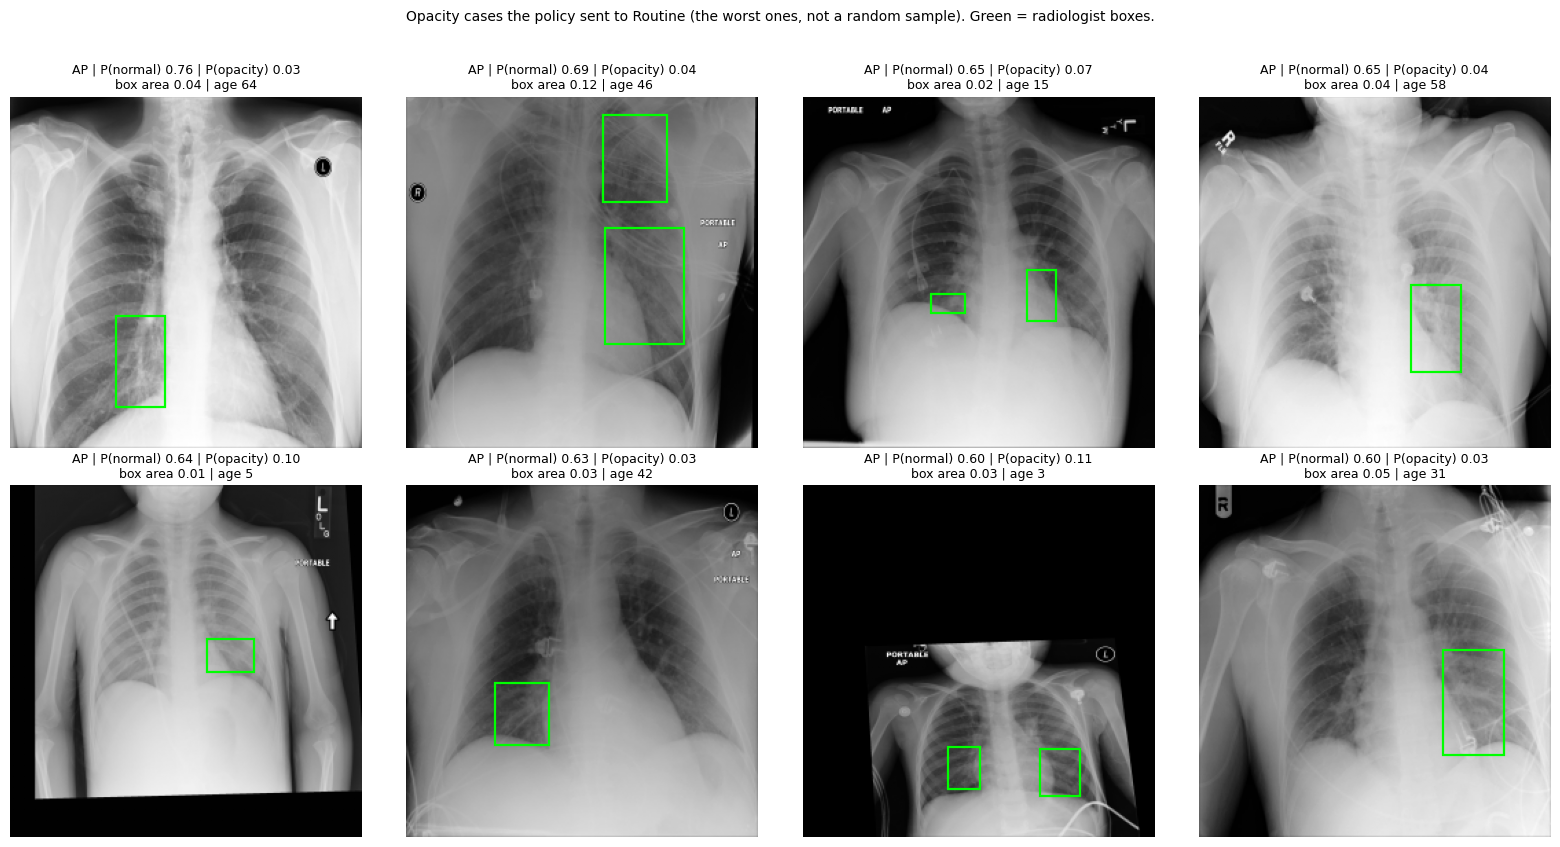

In [4]:
# Which opacity cases does the system miss? Compare caught (Urgent) with missed (Review soon or Routine).
S = 256 / 1024
boxes = pd.read_csv(find("boxes.csv")); boxes = boxes[boxes["Target"] == 1].dropna(subset=["x"])
BOX = {pid: g[["x", "y", "width", "height"]].values for pid, g in boxes.groupby("patientId")}
def box_mask(b):
    m = np.zeros((256, 256), bool)
    for x0, y0, w, h in b:
        m[int(y0 * S):int(np.ceil((y0 + h) * S)), int(x0 * S):int(np.ceil((x0 + w) * S))] = True
    return m

op = np.where(y_val == 2)[0]
info = va.iloc[op][["patientId", "view", "age", "sex"]].copy().reset_index(drop=True)
info["age"] = info["age"].where(info["age"] <= 100)                  # the age field contains invalid values such as 153
info["p_opacity"], info["p_normal"] = P_val[op, 2], P_val[op, 0]
info["caught"], info["routine"] = lvl_val[op] == 2, lvl_val[op] == 0
info["n_boxes"] = [len(BOX[p]) for p in info["patientId"]]
info["box_area"] = [box_mask(BOX[p]).mean() for p in info["patientId"]]   # share of the image covered by boxes

def describe(d):
    return {"n": len(d), "AP share": (d["view"] == "AP").mean(), "mean age": d["age"].mean(), "female share": (d["sex"] == "F").mean(),
            "median box area": d["box_area"].median(), "median boxes": d["n_boxes"].median(), "median P(opacity)": d["p_opacity"].median()}
cmp_ = pd.DataFrame({"caught (Urgent)": describe(info[info["caught"]]), "missed (not Urgent)": describe(info[~info["caught"]])})
print(cmp_.round(3))
for col in ["box_area", "n_boxes", "age"]:
    a, b = info.loc[info["caught"], col].dropna(), info.loc[~info["caught"], col].dropna()
    print(f"  {col:9s} caught vs missed: Mann-Whitney p = {mannwhitneyu(a, b).pvalue:.4f}")

# The most dangerous errors: opacity cases sent to Routine, ordered by how sure the model was that they were normal
bad = info[info["routine"]].sort_values("p_normal", ascending=False).head(8)
print(f"\nopacity cases sent to Routine: {int(info['routine'].sum())} of {len(info)} ({info['routine'].mean():.3f}); showing the {len(bad)} with the highest P(normal)")
if len(bad):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8.6))
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), bad.iterrows()):
        ax.imshow(IMGS[va.loc[va["patientId"] == r["patientId"], "idx"].values[0]], cmap="gray")
        for x0, y0, w, h in BOX[r["patientId"]]:
            ax.add_patch(plt.Rectangle((x0 * S, y0 * S), w * S, h * S, fill=False, ec="lime", lw=1.6))
        ax.set_title(f"{r['view']} | P(normal) {r['p_normal']:.2f} | P(opacity) {r['p_opacity']:.2f}\nbox area {r['box_area']:.2f} | age {r['age']:.0f}", fontsize=9)
    fig.suptitle("Opacity cases the policy sent to Routine (the worst ones, not a random sample). Green = radiologist boxes.", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=2.5); fig.savefig(OUT / "worst_misses.png", dpi=150); plt.show()
info.to_csv(OUT / "val_opacity_cases.csv", index=False)

=== FINAL TEST EVALUATION ===
{'macro_auroc': 0.883, 'macro_f1_argmax': 0.695, 'opacity_auroc': 0.887, 'opacity_pr_auc': 0.713, 'ece_p_opacity_calibrated': 0.028}
(validation for comparison: macro-AUROC 0.882, macro-F1 0.693, opacity AUROC 0.884, PR-AUC 0.692, ECE 0.030)

Policy C (per-view thresholds), validation vs test
                  urgent_recall  urgent_precision  opacity_to_routine  abnormal_to_routine  routine_share  urgent_share
group split                                                                                                            
AP    validation          0.801             0.603               0.014                0.042          0.119         0.504
      test                0.788             0.600               0.003                0.033          0.109         0.494
PA    validation          0.820             0.294               0.000                0.040          0.286         0.253
      test                0.774             0.292               0.031       

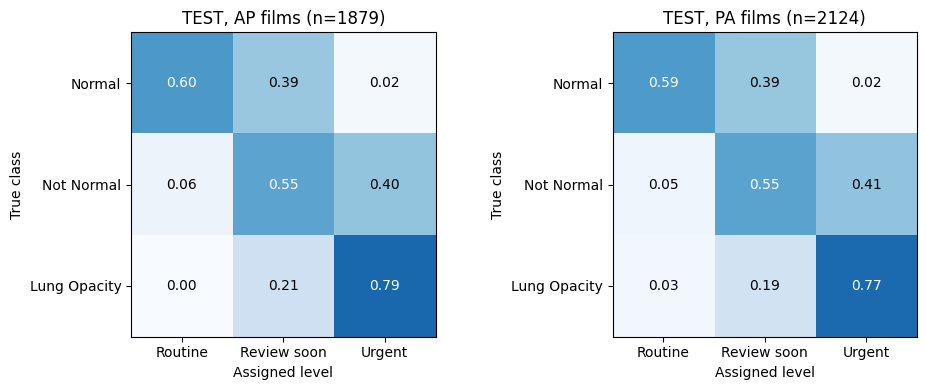

saved to /kaggle/working/final


In [5]:
# ================= PART B: FINAL TEST EVALUATION - RUN ONCE =================
# Calibration, thresholds and policy are frozen above. Do not change anything after seeing these numbers.
print("=== FINAL TEST EVALUATION ===")
y_te, v_te = te["label"].values, te["view"].values
p_te = predict_probs(model, te); P_te = calibrate(p_te)
lvl_te = apply_policy(P_te, v_te, TH)
lvl_te_unk = apply_policy(P_te, v_te, {"AP": TH_UNKNOWN, "PA": TH_UNKNOWN})

t_op_te = (y_te == 2).astype(int)
model_metrics = {"macro_auroc": roc_auc_score(y_te, p_te, multi_class="ovr", average="macro"),
                 "macro_f1_argmax": f1_score(y_te, p_te.argmax(1), average="macro"),
                 "opacity_auroc": roc_auc_score(t_op_te, p_te[:, 2]), "opacity_pr_auc": average_precision_score(t_op_te, p_te[:, 2]),
                 "ece_p_opacity_calibrated": ece_binary(P_te[:, 2], t_op_te)}
print({k: round(float(v), 3) for k, v in model_metrics.items()})
print("(validation for comparison: macro-AUROC 0.882, macro-F1 0.693, opacity AUROC 0.884, PR-AUC 0.692, ECE 0.030)")

rows = []
for split, y_, v_, l_ in [("validation", y_val, v_val, lvl_val), ("test", y_te, v_te, lvl_te)]:
    for g, m in group_masks(v_):
        rows.append({"split": split, "group": g, **triage_metrics(y_[m], l_[m])})
vt = pd.DataFrame(rows).set_index(["group", "split"]).sort_index(level=0, sort_remaining=False)
print("\nPolicy C (per-view thresholds), validation vs test"); print(vt.round(3))

rng = np.random.default_rng(42)
KEYS = ["urgent_recall", "opacity_to_routine", "abnormal_to_routine", "routine_share"]
boot = {(g, k): [] for g, _ in group_masks(v_te) for k in KEYS}
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    yy, vv, ll = y_te[i], v_te[i], lvl_te[i]
    for g, m in group_masks(vv):
        mt = triage_metrics(yy[m], ll[m])
        for k in KEYS: boot[(g, k)].append(mt[k])
print("\nTEST, 95% bootstrap intervals")
final = {}
for g, m in group_masks(v_te):
    pt = triage_metrics(y_te[m], lvl_te[m])
    for k in KEYS:
        lo, hi = np.nanpercentile(boot[(g, k)], [2.5, 97.5])
        final[f"{g}_{k}"] = [float(pt[k]), float(lo), float(hi)]
        print(f"  {g:3s} {k:20s} {pt[k]:.3f}   (95% CI {lo:.3f} - {hi:.3f})")

unk = triage_metrics(y_te, lvl_te_unk)
print("\nView-unknown fallback (strictest thresholds), test:", {k: round(float(v), 3) for k, v in unk.items()})

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, v in zip(axes, ["AP", "PA"]):
    m = v_te == v
    t = level_table(y_te[m], lvl_te[m]); t = t.div(t.sum(axis=1), axis=0)
    ax.imshow(t.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(NAMES_L); ax.set_yticks(range(3)); ax.set_yticklabels(NAMES_C)
    for i in range(3):
        for j in range(3): ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", color="white" if t.values[i, j] > 0.5 else "black")
    ax.set_title(f"TEST, {v} films (n={int(m.sum())})"); ax.set_xlabel("Assigned level"); ax.set_ylabel("True class")
fig.tight_layout(); fig.savefig(OUT / "test_triage_confusion.png", dpi=150); plt.show()

json.dump({"note": "single run on the held-out test set; thresholds, calibration and policy frozen from notebook 03b",
           "model_metrics": {k: float(v) for k, v in model_metrics.items()}, "policy_C_ci": final,
           "view_unknown_policy": {k: float(v) for k, v in unk.items()}}, open(OUT / "test_results.json", "w"), indent=2)
vt.to_csv(OUT / "validation_vs_test.csv")
print("saved to", OUT)